<a href="https://colab.research.google.com/github/Mathanprasath-T/language_identification/blob/main/language_identification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files
uploaded=files.upload()

Saving dataset.csv to dataset.csv


In [4]:
import re
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

df = pd.read_csv("dataset.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (22000, 2)

Column names: ['Text', 'language']

First five rows:


,Text,language
0,klement gottwaldi surnukeha palsameeriti ning ...,Estonian
1,sebes joseph pereira thomas på eng the jesuit...,Swedish
2,ถนนเจริญกรุง อักษรโรมัน thanon charoen krung เ...,Thai
3,விசாகப்பட்டினம் தமிழ்ச்சங்கத்தை இந்துப் பத்திர...,Tamil
4,de spons behoort tot het geslacht haliclona en...,Dutch



Missing values:
Text        0
language    0
dtype: int64


In [14]:
# Use the full cleaned dataset
data = df[["Text", "language"]].copy()

data = data.dropna()
data["Text"] = data["Text"].astype(str).str.strip()
data["language"] = data["language"].astype(str).str.strip()

data = data[
    (data["Text"] != "") &
    (data["language"] != "")
].drop_duplicates(
    subset=["Text", "language"]
).reset_index(drop=True)

# Preserve Unicode characters and punctuation
def prepare_text(text):
    text = str(text).lower()
    text = re.sub(r"\s+", " ", text).strip()
    return text

data["model_text"] = data["Text"].apply(prepare_text)

X = data["model_text"].values
y_text = data["language"].values

label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y_text)

num_classes = len(label_encoder.classes_)

print("Total samples:", len(data))
print("Number of languages:", num_classes)
print("Language names:", list(label_encoder.classes_))
print(data["language"].value_counts())

Total samples: 21858
Number of languages: 22
Language names: ['Arabic', 'Chinese', 'Dutch', 'English', 'Estonian', 'French', 'Hindi', 'Indonesian', 'Japanese', 'Korean', 'Latin', 'Persian', 'Portugese', 'Pushto', 'Romanian', 'Russian', 'Spanish', 'Swedish', 'Tamil', 'Thai', 'Turkish', 'Urdu']
language
Japanese      1000
Thai          1000
Korean        1000
Chinese       1000
Urdu          1000
Turkish       1000
Romanian      1000
English       1000
Persian       1000
Estonian       999
Russian        999
Arabic         998
Portugese      997
Spanish        996
Dutch          995
Pushto         993
Swedish        992
French         990
Hindi          990
Tamil          981
Indonesian     975
Latin          953
Name: count, dtype: int64


In [15]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from sklearn.model_selection import train_test_split

# 80% training, 20% testing
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Tokenize individual characters instead of whole words
tokenizer = Tokenizer(
    char_level=True,
    lower=False,
    filters="",
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

# Use a fixed sequence length
MAX_LENGTH = 200

X_train = pad_sequences(
    X_train_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

X_test = pad_sequences(
    X_test_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

vocab_size = len(tokenizer.word_index) + 1

print("Vocabulary size:", vocab_size)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Vocabulary size: 6807
Training shape: (17486, 200)
Testing shape: (4372, 200)
Training samples: 17486
Testing samples: 4372


In [16]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Dense, Dropout, Bidirectional
)
from tensorflow.keras.optimizers import Adam

model = Sequential([
    Embedding(
        input_dim=vocab_size,
        output_dim=64,
        mask_zero=True
    ),

    Bidirectional(LSTM(64)),

    Dropout(0.40),

    Dense(64, activation="relu"),

    Dropout(0.20),

    Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=1,
    min_lr=0.00001,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.10,
    epochs=8,
    batch_size=128,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 113s 920ms/step - accuracy: 0.8404 - loss: 0.4282 - val_accuracy: 0.8553 - val_loss: 0.3855 - learning_rate: 3.1250e-05
Epoch 2/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 752ms/step - accuracy: 0.8353 - loss: 0.4357
Epoch 2: ReduceLROnPlateau reducing learning rate to 1.5625000742147677e-05.
123/123 ━━━━━━━━━━━━━━━━━━━━ 95s 773ms/step - accuracy: 0.8430 - loss: 0.4235 - val_accuracy: 0.8553 - val_loss: 0.3873 - learning_rate: 3.1250e-05
Epoch 3/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 95s 776ms/step - accuracy: 0.8458 - loss: 0.4231 - val_accuracy: 0.8542 - val_loss: 0.3825 - learning_rate: 1.5625e-05
Epoch 4/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 735ms/step - accuracy: 0.8411 - loss: 0.4309
Epoch 4: ReduceLROnPlateau reducing learning rate to 1e-05.
123/123 ━━━━━━━━━━━━━━━━━━━━ 96s 777ms/step - accuracy: 0.8448 - loss: 0.4181 - val_accuracy: 0.8531 - val_loss: 0.3869 - learning_rate: 1.5625e-05
Epoch 5/8
123/123 ━━━━━━━━━━━━━━━━━━━━ 94s 764ms/step - accuracy: 0.8410 - l

In [22]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = model.fit(
    X_train,
    y_train,
    validation_split=0.15,
    epochs=3,
    batch_size=28,
    callbacks=[early_stop, reduce_lr],
    verbose=1
)

Epoch 1/3
531/531 ━━━━━━━━━━━━━━━━━━━━ 159s 298ms/step - accuracy: 0.8420 - loss: 0.4180 - val_accuracy: 0.8559 - val_loss: 0.3883 - learning_rate: 1.0000e-05
Epoch 2/3
531/531 ━━━━━━━━━━━━━━━━━━━━ 193s 281ms/step - accuracy: 0.8451 - loss: 0.4138 - val_accuracy: 0.8574 - val_loss: 0.3862 - learning_rate: 1.0000e-05
Epoch 3/3
531/531 ━━━━━━━━━━━━━━━━━━━━ 202s 282ms/step - accuracy: 0.8468 - loss: 0.4042 - val_accuracy: 0.8563 - val_loss: 0.3858 - learning_rate: 1.0000e-05


In [23]:
from sklearn.metrics import accuracy_score, classification_report

y_pred_prob = model.predict(X_test)
y_pred = y_pred_prob.argmax(axis=1)

# Convert one-hot labels to class IDs if necessary
import numpy as np

y_true = (
    y_test.argmax(axis=1)
    if np.asarray(y_test).ndim > 1
    else np.asarray(y_test)
)

print("Test Accuracy:", accuracy_score(y_true, y_pred))
print(classification_report(y_true, y_pred))

137/137 ━━━━━━━━━━━━━━━━━━━━ 14s 87ms/step
Test Accuracy: 0.8538426349496798
              precision    recall  f1-score   support

           0       0.99      1.00      1.00       200
           1       0.98      0.99      0.99       200
           2       0.84      0.85      0.84       199
           3       0.70      0.90      0.79       200
           4       0.76      0.46      0.57       200
           5       0.56      0.85      0.68       198
           6       0.96      0.96      0.96       198
           7       0.61      0.82      0.70       195
           8       1.00      0.99      1.00       200
           9       1.00      0.99      1.00       200
          10       0.67      0.17      0.28       191
          11       0.99      0.99      0.99       200
          12       0.47      0.38      0.42       199
          13       1.00      0.92      0.96       199
          14       0.97      0.97      0.97       200
          15       1.00      0.98      0.99       200
    

In [24]:
# Get predicted probabilities and select the highest-scoring class
y_prob = model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print(f"Accuracy : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1-score : {f1:.4f}")

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=label_encoder.classes_,
    zero_division=0
))

Accuracy : 0.8538 (85.38%)
Precision: 0.8591
Recall   : 0.8538
F1-score : 0.8451

Detailed classification report:
              precision    recall  f1-score   support

      Arabic       0.99      1.00      1.00       200
     Chinese       0.98      0.99      0.99       200
       Dutch       0.84      0.85      0.84       199
     English       0.70      0.90      0.79       200
    Estonian       0.76      0.46      0.57       200
      French       0.56      0.85      0.68       198
       Hindi       0.96      0.96      0.96       198
  Indonesian       0.61      0.82      0.70       195
    Japanese       1.00      0.99      1.00       200
      Korean       1.00      0.99      1.00       200
       Latin       0.67      0.17      0.28       191
     Persian       0.99      0.99      0.99       200
   Portugese       0.47      0.38      0.42       199
      Pushto       1.00      0.92      0.96       199
    Romanian       0.97      0.97      0.97       200
     Russian       1.

In [25]:
unseen_texts = [
    "The weather is beautiful today and I am going to the library.",
    "Bonjour, je voudrais apprendre une nouvelle langue.",
    "Hola, hoy quiero aprender un idioma nuevo.",
    "இன்று நான் ஒரு புதிய மொழியைக் கற்க விரும்புகிறேன்.",
    "आज मैं एक नई भाषा सीखना चाहता हूँ।"
]

# Apply exactly the same preprocessing
clean_unseen = [
    preprocess_text(text) for text in unseen_texts
]

# Use the existing tokenizer, not a newly fitted tokenizer
unseen_seq = tokenizer.texts_to_sequences(clean_unseen)

unseen_pad = pad_sequences(
    unseen_seq,
    maxlen=MAX_LENGTH,
    padding="post",
    truncating="post"
)

# Predict language probabilities
unseen_prob = model.predict(unseen_pad, verbose=0)

for i, text in enumerate(unseen_texts):
    predicted_id = int(np.argmax(unseen_prob[i]))
    predicted_language = label_encoder.inverse_transform(
        [predicted_id]
    )[0]
    confidence = float(np.max(unseen_prob[i])) * 100

    print(f"\nText {i + 1}: {text}")
    print("Predicted language:", predicted_language)
    print(f"Model confidence: {confidence:.2f}%")


Text 1: The weather is beautiful today and I am going to the library.
Predicted language: English
Model confidence: 86.12%

Text 2: Bonjour, je voudrais apprendre une nouvelle langue.
Predicted language: Spanish
Model confidence: 40.49%

Text 3: Hola, hoy quiero aprender un idioma nuevo.
Predicted language: Portugese
Model confidence: 44.44%

Text 4: இன்று நான் ஒரு புதிய மொழியைக் கற்க விரும்புகிறேன்.
Predicted language: Arabic
Model confidence: 63.25%

Text 5: आज मैं एक नई भाषा सीखना चाहता हूँ।
Predicted language: Hindi
Model confidence: 99.61%


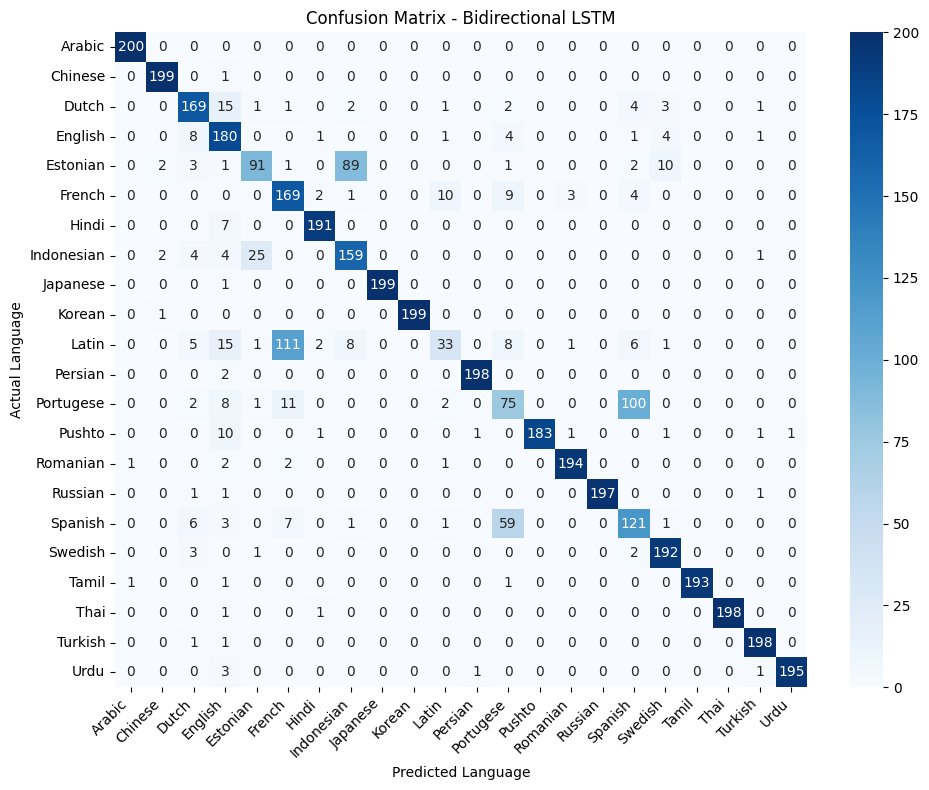

In [27]:

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# Create confusion matrix
cm = confusion_matrix(y_true, y_pred)

# Get language names from your trained label encoder, if available
# Change label_encoder to your actual encoder variable name
try:
    class_names = label_encoder.classes_
except NameError:
    class_names = [str(i) for i in range(cm.shape[0])]

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Language")
plt.ylabel("Actual Language")
plt.title("Confusion Matrix - Bidirectional LSTM")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()
